# 06 · BG/NBD: байесовский фит, варианты и диагностика

Шаг 7 плана. Основной фит — BG/NBD на всех клиентах калибровки, включая
`frequency = 0` (правдоподобие определено при x = 0). Отдельно — фит без
одноразовых покупателей: экспонат о том, что даёт популярная ошибка фильтрации.
Сравнение — с Pareto/NBD и MBG/NBD по log-likelihood, AIC и holdout.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
from inspect import signature
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, PROCESSED, RANDOM_SEED, figures
from features import (CUTOFF_DATE, HORIZON_MONTHS, B3_T_DAYS, B3_FIT_MONTHS,
                      DAYS_IN_AGE_MONTH, split_transactions, calibration_features,
                      calibration_revenue, build_target, lifecycle_transactions,
                      first_purchase_dates, pre_first_mask, customer_country,
                      cohort_tables, pooled_curve, extend_survival,
                      extend_cumulative_revenue, age_months)
from metrics import (gini, top_capture, top_lift, decile_capture, lorenz_points,
                     mae, rmse, calibration_ratio, model_metrics, bootstrap_ci,
                     bootstrap_diff, calibration_by, coverage_at_top,
                     smallest_segment_for_coverage, shrink_predictions)
from models import (fit_bgnbd, fit_mbg_nbd, fit_pareto_nbd, fit_gamma_gamma,
                    bgnbd_loglik, bgnbd_expected_purchases, mbg_nbd_loglik,
                    mbg_nbd_expected_purchases, pareto_nbd_loglik,
                    pareto_nbd_expected_purchases, gamma_gamma_loglik,
                    gamma_gamma_mean, gamma_gamma_conditional_spend,
                    monthly_expected_purchases, discounted_revenue, aic)
from plots import (plot_split_timeline, plot_lorenz, plot_model_comparison,
                   plot_calibration_by_decile, plot_horizon, plot_segments,
                   plot_shrinkage, plot_posterior)
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')

split = pd.read_parquet(PROCESSED / 'ltv_split.parquet')
d = split[split['T'] > 0].copy()
x = d.frequency.to_numpy(float)
t_x = d.recency.to_numpy(float)
T = d['T'].to_numpy(float)
print('клиентов в фите:', len(d), '· frequency = 0:', f'{(x == 0).mean():.1%}')


клиентов в фите: 4239 · frequency = 0: 35.2%


## Байесовский BG/NBD (PyMC-Marketing)

In [2]:
from pymc_marketing.clv import BetaGeoModel

data_bayes = d.reset_index()[['customer_id', 'frequency', 'recency', 'T']]
model = BetaGeoModel()
model.fit(data_bayes, draws=500, tune=500, chains=4, cores=1,
          target_accept=0.9, progressbar=False, random_seed=RANDOM_SEED)
summary = model.fit_summary()
summary.round(4)


g++ not available, if using conda: `conda install gxx`


C:\Users\anton.aleksishin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [alpha, phi_dropout, kappa_dropout, r]


C:\Users\anton.aleksishin\AppData\Local\Programs\Python\Python312\Lib\site-packages\pymc\step_methods\hmc\quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 120 seconds.


C:\Users\anton.aleksishin\AppData\Local\Programs\Python\Python312\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha,66,2.27,62,70,916,1183,1.00,0.075,0.049
phi_dropout,0.0041,0.0023,0.0013,0.0082,1112,981,1.00,6.4e-05,6.3e-05
kappa_dropout,2.87e+01,2.59e+02,1.3,47,1499,1383,1.00,7.6,72
r,0.824,0.025,0.79,0.86,1029,1270,1.00,0.00076,0.00053
a,0.06,0.4,0.0039,0.13,1456,792,1.00,0.013,0.13
b,2.86e+01,2.58e+02,1.2,47,1498,1383,1.00,7.5,72


## §5а-6: диагностика MCMC — числами

Не меньше двух цепочек, `r_hat < 1.01`, `ess_bulk > 400`, расхождения — из
`az.summary`/`fit_summary`, не с графика.

In [3]:
s = summary.loc[['r', 'alpha', 'a', 'b']]
assert model.idata.posterior.sizes['chain'] >= 2
assert (s.r_hat < 1.01).all(), s[['r_hat']]
assert (s.ess_bulk > 400).all(), s[['ess_bulk']]
divergences = int(model.idata.sample_stats['diverging'].sum())
assert divergences == 0, divergences
print('r_hat max:', round(float(s.r_hat.max()), 4), '· ess_bulk min:', round(float(s.ess_bulk.min())))
print('divergences:', divergences)


r_hat max: 1.0025 · ess_bulk min: 916
divergences: 0


## §5а-1: параметрическое среднее против эмпирического

In [4]:
r_mean, alpha_mean = float(s.loc['r', 'mean']), float(s.loc['alpha', 'mean'])
emp = (x / T).mean()
assert abs(np.log10(r_mean / alpha_mean) - np.log10(emp)) < 1, 'rate vs scale?'
print('r/alpha =', round(r_mean / alpha_mean, 5), '· mean(f/T) =', round(emp, 5))


r/alpha = 0.01249 · mean(f/T) = 0.01139


## §5а-5: один общий индекс draw

Параметры постериора нельзя пересэмплировать независимо: это разрушает совместное
распределение. Беру 200 draw одним индексом и проверяю, что корреляция `a,b`
сохраняется.

In [5]:
post = model.idata.posterior.to_dataset().stack(sample=('chain', 'draw'))
idx = RNG.choice(post.sizes['sample'], size=200, replace=False)
r_draw = post['r'].to_numpy()[idx]
alpha_draw = post['alpha'].to_numpy()[idx]
a_draw = post['a'].to_numpy()[idx]
b_draw = post['b'].to_numpy()[idx]
corr_joint = np.corrcoef(a_draw, b_draw)[0, 1]
corr_full = np.corrcoef(post['a'].to_numpy(), post['b'].to_numpy())[0, 1]
assert abs(corr_joint - corr_full) < 0.05, (corr_joint, corr_full)
print('corr(a,b) joint:', round(corr_joint, 3), '· full posterior:', round(corr_full, 3))


corr(a,b) joint: 0.905 · full posterior: 0.926


## Прогноз покупок: среднее по 200 joint draw

In [6]:
pred_draws = np.vstack([
    bgnbd_expected_purchases((r_draw[i], alpha_draw[i], a_draw[i], b_draw[i]), x, t_x, T, 365)
    for i in range(len(idx))
])
pred_bayes = pred_draws.mean(axis=0)
print('E[покупок за 12 мес] mean:', round(pred_bayes.mean(), 2))
print('факт: дней с покупкой в holdout mean:', round(d.purchase_days_holdout.mean(), 2))


E[покупок за 12 мес] mean: 4.38
факт: дней с покупкой в holdout mean: 2.9


## MLE: полная выборка и выборка без одноразовых покупателей

In [7]:
p_full, res_full = fit_bgnbd(x, t_x, T)
mask = x > 0
p_nonone, res_nonone = fit_bgnbd(x[mask], t_x[mask], T[mask])
pred_full = bgnbd_expected_purchases(p_full, x, t_x, T, 365)
pred_nonone = bgnbd_expected_purchases(p_nonone, x, t_x, T, 365)
ll_full = float(np.sum(bgnbd_loglik(p_full, x, t_x, T)))
ll_nonone = float(np.sum(bgnbd_loglik(p_nonone, x[mask], t_x[mask], T[mask])))
print('full params:', np.round(p_full, 4), '· loglik', round(ll_full, 1))
print('no-one-time params:', np.round(p_nonone, 4), '· loglik', round(ll_nonone, 1))
print('pred purchases full:', round(pred_full.mean(), 2), '· no-one-time applied to all:', round(pred_nonone.mean(), 2))
print('actual purchase days:', round(d.purchase_days_holdout.mean(), 2))


full params: [  0.9061  75.252    0.1656 100.    ] · loglik -59811.1
no-one-time params: [1.982400e+00 1.144288e+02 1.560000e-02 3.706000e-01] · loglik -58211.2
pred purchases full: 4.34 · no-one-time applied to all: 5.05
actual purchase days: 2.9


Экспонат: фит без `frequency = 0` видит только «выживших», завышает
`p(alive)` и суммарный прогноз. Сравнение — в таблице ниже и в README.

## Pareto/NBD и MBG/NBD

In [8]:
p_mbg, res_mbg = fit_mbg_nbd(x, t_x, T)
p_par, res_par = fit_pareto_nbd(x, t_x, T, n=16)
ll_mbg = float(np.sum(mbg_nbd_loglik(p_mbg, x, t_x, T)))
ll_par = float(np.sum(pareto_nbd_loglik(p_par, x, t_x, T, n=16)))
pred_mbg = mbg_nbd_expected_purchases(p_mbg, x, t_x, T, 365)
pred_par = pareto_nbd_expected_purchases(p_par, x, t_x, T, 365, n=16)
fit_table = pd.DataFrame({
    'model': ['BG/NBD (MLE)', 'MBG/NBD', 'Pareto/NBD'],
    'loglik': [ll_full, ll_mbg, ll_par],
    'aic': [aic(ll_full, 4), aic(ll_mbg, 4), aic(ll_par, 4)],
    'mean_purchases_12m': [pred_full.mean(), pred_mbg.mean(), pred_par.mean()],
})
fit_table.round(2)


,model,loglik,aic,mean_purchases_12m
0,BG/NBD (MLE),-59811.06,119630.12,4.34
1,MBG/NBD,-59814.30,119636.60,4.36
2,Pareto/NBD,-59802.51,119613.02,4.37


In [9]:
params = pd.DataFrame({
    'BG/NBD (MLE)': p_full, 'MBG/NBD': p_mbg, 'Pareto/NBD': p_par,
}, index=['r', 'alpha', 'a_or_s', 'b_or_beta'])
params.round(4)


,BG/NBD (MLE),MBG/NBD,Pareto/NBD
r,0.9061,0.9107,1.0418
alpha,75.2520,75.9699,86.5295
a_or_s,0.1656,0.0301,1.2169
b_or_beta,100.0000,100.0000,100000.0000


Pareto/NBD уходит в границу `beta → ∞`: отток не идентифицируется, модель
вырождается в NBD. AIC формально чуть лучше, но параметр на границе — сравнивать
по AIC нельзя. MBG/NBD тоже уходит в `b → 100`. Это результат: три модели
различаются слабо, выбираю BG/NBD по простоте и интерпретируемости.

## Сохранение постериора и прогнозов

In [10]:
draws = pd.DataFrame({k: model.idata.posterior[k].to_numpy().ravel()
                      for k in ['r', 'alpha', 'a', 'b']})
draws['chain'] = np.repeat(np.arange(model.idata.posterior.sizes['chain']),
                           model.idata.posterior.sizes['draw'])
draws['draw'] = np.tile(np.arange(model.idata.posterior.sizes['draw']),
                        model.idata.posterior.sizes['chain'])
draws.to_parquet(PROCESSED / 'bgnbd_posterior.parquet')
summary.to_csv(PROCESSED / 'bgnbd_summary.csv')
predictions = pd.DataFrame({
    'BG_bayes': pred_bayes, 'BG_mle': pred_full, 'BG_no_one_time': pred_nonone,
    'MBG': pred_mbg, 'Pareto': pred_par,
}, index=d.index)
predictions.to_parquet(PROCESSED / 'purchases.parquet')
fit_table.to_csv(PROCESSED / 'frequency_model_fit.csv', index=False)
params.to_csv(PROCESSED / 'frequency_model_params.csv')
assert predictions.notna().all().all() and (predictions >= 0).all().all()


## Графики диагностики

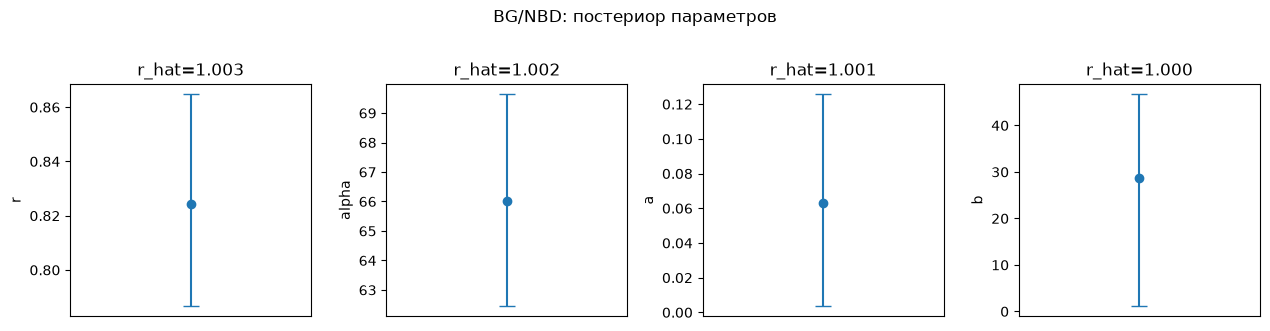

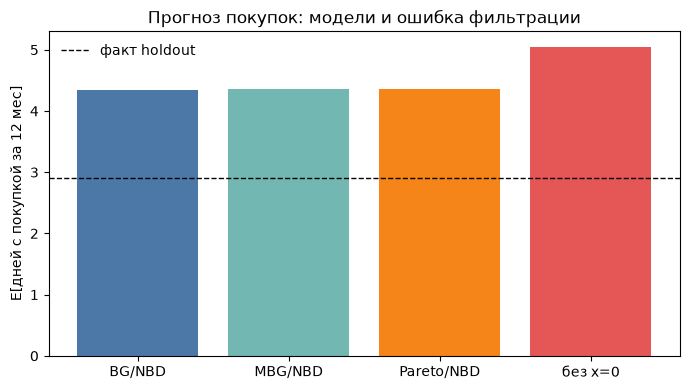

In [11]:
plot_posterior(summary, FIG / '09-bgnbd-posterior.png')
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
labels = ['BG/NBD', 'MBG/NBD', 'Pareto/NBD', 'без x=0']
vals = [pred_full.mean(), pred_mbg.mean(), pred_par.mean(), pred_nonone.mean()]
ax.bar(labels, vals, color=['#4C78A8', '#72B7B2', '#F58518', '#E45756'])
ax.axhline(d.purchase_days_holdout.mean(), color='black', ls='--', lw=1, label='факт holdout')
ax.set(ylabel='E[дней с покупкой за 12 мес]', title='Прогноз покупок: модели и ошибка фильтрации')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / '10-purchase-models.png'); plt.show()


Все три модели дают близкий прогноз покупок; фит без одноразовых покупателей
заметно выше факта. Это и есть цена популярной ошибки: модель учится на «выживших»
и переносит их поведение на всю базу.